### Homework 8 ###

In [3]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.noise import NoiseModel

##### Ideal Reference Circuit #####

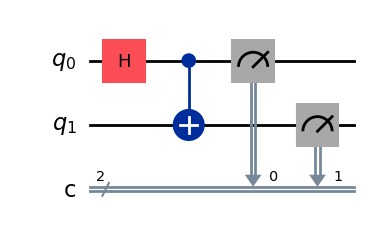

In [4]:
qc = QuantumCircuit(2,2)
qc.h(0)
qc.cx(0,1)
qc.measure([0,1],[0,1])
qc.draw('mpl')

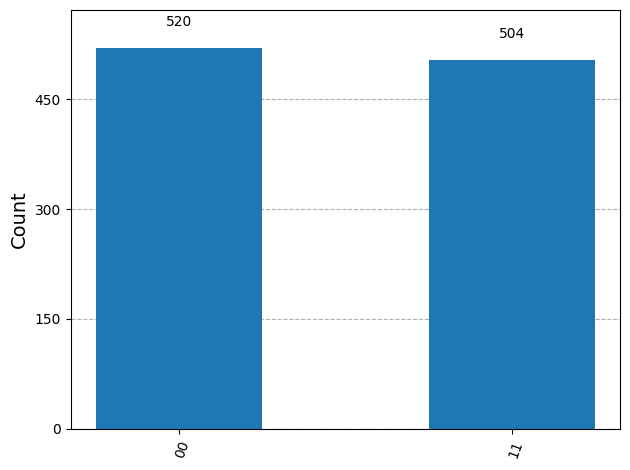

In [5]:
ideal_backend = AerSimulator()
transpiled_qc = transpile(qc, ideal_backend)
job = ideal_backend.run(transpiled_qc, shots=1024)
ideal_counts = job.result().get_counts()
plot_histogram(ideal_counts)

##### Constructing a Noise Model

In [6]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

#Initialize the noise model
noise_model = NoiseModel()

# 1-qubit depolarizing error (1% error)
p1 = 0.01
error_1q = depolarizing_error(p1,1)

# 2-qubit depolarizing error (5% error)
p2 = 0.05
error_2q = depolarizing_error(p2, 2)

# Apply errors to specific gates
noise_model.add_all_qubit_quantum_error(error_1q, ['h'])
noise_model.add_all_qubit_quantum_error(error_2q, ['cx'])

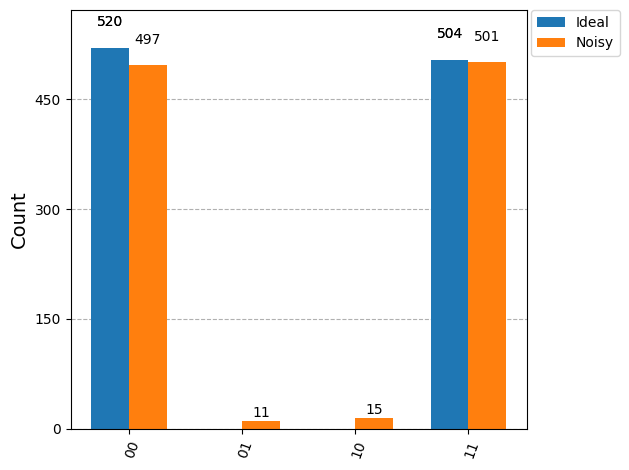

In [7]:
noisy_backend = AerSimulator(noise_model = noise_model)
tqc = transpile(qc, noisy_backend)
job = noisy_backend.run(tqc, shots=1024)
noisy_counts = job.result().get_counts()
plot_histogram([ideal_counts,noisy_counts], legend=['Ideal', 'Noisy'])

Why does the CNOT gate dominate the error?
    The CNOT gate has a 2-qubit depolarizing error which has a stronger error compared to the H gate
Why do incorrect outcomes appear?
    The error only effects one qubit in some senerios, thus leading to non-matching states.

##### Exercise: Exploring Noise Strength

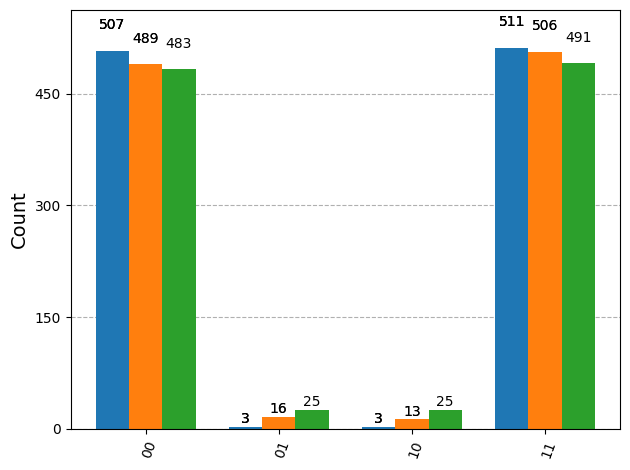

In [17]:
p2_values = [0.01, 0.05, 0.1]
results = []

for p in p2_values:
    # 1. Setup noise model
    nm = NoiseModel()
    error_2q = depolarizing_error(p, 2)
    nm.add_all_qubit_quantum_error(error_2q, ['cx'])

    # 2. Attach noise model to the backend
    noisy_backend = AerSimulator(noise_model = nm)

    # 3. Transpile for this specific backend
    transpiled_qc = transpile(qc, noisy_backend)

    # 4. Run the circuit
    job = noisy_backend.run(transpiled_qc, shots = 1024)
    results.append(job.result().get_counts())
# plot_histogram([ideal_counts,noisy_counts], legend=['Ideal', 'Noisy'])
plot_histogram(results)



Which gate dominates the error?
    The CNOT gate acts on two qubits, which means that we are causing error on a 4-dimensional state space instead of a 2-dimensional state space
    
When does the result become useless?
    The result becomes useless when the distribution looks like a random distribution, there would be no correlation.

##### Exercise: Decoherence Noise Model

In [19]:
from qiskit_aer.noise import NoiseModel, amplitude_damping_error, phase_damping_error
# 1. Define strengths
gamma_T1 = 0.05 # amplitude damping strength
lambda_T2 = 0.08 # phase damping strength

# 2. Create the errors (from qiskit_aer.noise)
T1_error = amplitude_damping_error(gamma_T1)
T2_error = phase_damping_error(lambda_T2)

# 3. Build the model
decoherence_noise = NoiseModel()

# 4. Compose and apply errors (usually applied to identity or single-qubit gates)
# You can compose them using the dot product for a combined effect
combined_error = T1_error.compose(T2_error)

decoherence_noise.add_all_qubit_quantum_error(combined_error, ['id', 'rz'])


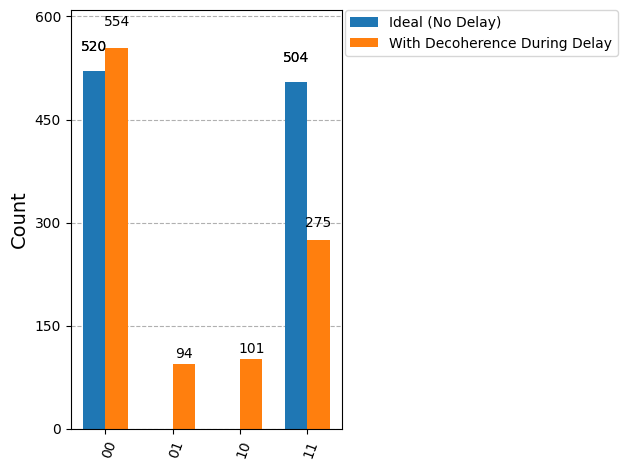

In [29]:
from qiskit_aer.noise import thermal_relaxation_error
# This qubit relaxes on a 30 micro-s timescale and dephases on a 20 micro-s timescale.
T1 = 30000 # ns
T2 = 20000 # ns
delay_time = 10000 # 500 ns

decoherence_noise = NoiseModel()

# tells the simulatior what happens during that wait.
# Given a qubit with relaxation time T1 and dephasing time T2, how much does it decohere during this much time?

delay_error = thermal_relaxation_error(t1 = T1, t2 = T2, time = delay_time)

# Add the same error model to every delay instruction on all qubits
# Whenever the circuit has a delay instruction, apply this delay_error noise model.
decoherence_noise.add_all_qubit_quantum_error(delay_error, ['delay'])

# Define the circuit with a Delay
qc_decoh = QuantumCircuit(2, 2)
qc_decoh.h(0)
qc_decoh.cx(0,1)

# Simulate waiting time using a delay of 500 nanoseconds
# 'ns' is the set unit, 's', 'ms', 'us', and 'dt; are also supported
qc_decoh.delay(delay_time, unit='ns') # Tells the circuit how long it waits

qc_decoh.measure([0,1],[0,1])

# Setup the backend
noisy_backend = AerSimulator(noise_model = decoherence_noise)

# Transpile (Optimization level - is still safest to keep the delay intact)
t_qc_decoh = transpile(qc_decoh, noisy_backend, optimization_level = 0)
decoh_counts = noisy_backend.run(t_qc_decoh, shots=1024).result().get_counts()

# Plot
plot_histogram([ideal_counts, decoh_counts], legend = ['Ideal (No Delay)', 'With Decoherence During Delay'])

Which outcome increases due to T1 relaxation?
    It appears that the 00 outcome is increased.

How is this effect diffenet from depolarizing noise?
    Depolorizing noise doesnt "favor" a result where as the T1 relaxation pushes twoards 00

Why does adding idle time make things worse?
    By adding idle times, more time is given for the qubits to dephase


##### Readout Errors

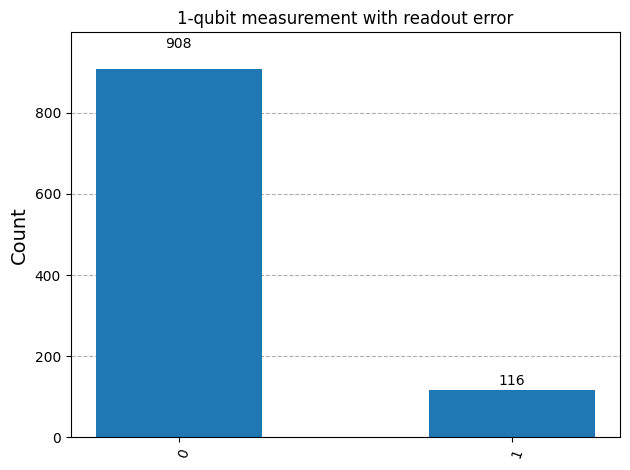

In [30]:
from qiskit_aer.noise import NoiseModel, ReadoutError

# Define the assignment matrix
# [[P(0|0), P(1|0)],
#  [P(0|1), P(1|1)]]
probabilities = [[.9,.1],[.2,.8]]

readout_error = ReadoutError(probabilities)

# Initialize and add to model
noise_model_ro = NoiseModel()
noise_model_ro.add_all_qubit_readout_error(readout_error)

# Simple 1-qubit circuit: prepare |0>
qc = QuantumCircuit(1,1)
qc.measure(0,0) # noisy measurement under noise_model_ro

# Run with noisy simulator
backend = AerSimulator(noise_model = noise_model_ro)
tqc = transpile(qc, backend)
result = backend.run(tqc, shots=1024).result()
counts = result.get_counts()

# Plot histograms
plot_histogram(counts, title = '1-qubit measurement with readout error')

##### Simulating a Real Device with a Fake Backend

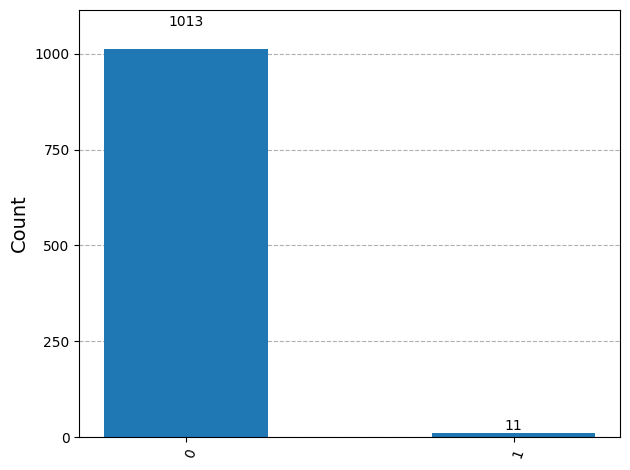

In [35]:
from qiskit_ibm_runtime.fake_provider import FakeVigoV2
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit.visualization import plot_histogram

# 1. Load a realistic fake backend
fake_backend = FakeVigoV2()

# 2. Create a noisy simulator from the backend
realistic_simulator = AerSimulator.from_backend(fake_backend)

# 3. Transpile the circuit for this backend
transpiled_qc = transpile(qc, realistic_simulator)

# 4. Run the simulation
job = realistic_simulator.run(transpiled_qc, shots=1024)
realistic_counts = job.result().get_counts()

# 5. Plot the results
plot_histogram(realistic_counts)

##### Reflection Questions
Which noise source was most damaging?
    Two qubit gate noise on the CNot seem like the most damaging as it directly affects entaglement

Why are two-qubit gates problematic?
    They are noisier than single qubit gates and harder to implement

Why does increasing the number of shots not fix noise?
    The number of shots doesnt change noise, only statistical uncertainty

Why is error mitigation necessary?
    It helps to undo error caused from quantum noise